KMEANS

In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt 

df = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/country_data.csv")
df

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
...,...,...,...,...,...,...,...,...,...,...
162,Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,Venezuela,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,Vietnam,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,Yemen,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310


DATA CLEANING

In [2]:
df.isnull().sum()

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [3]:
df.drop_duplicates(inplace=True)

In [4]:
# q1 = df["gdpp"].quantile(0.25)
# q3 = df["gdpp"].quantile(0.75)
# iqr = q3 - q1

# lower = q1 - 1.5 * iqr
# upper = q3 + 1.5 * iqr 

# df_clean = df[(df["gdpp"] >= lower) & (df["gdpp"] <= upper)]
# df_clean

In [5]:
x = df[["income", "life_expec"]]

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)

x_scaled

array([[8.04720599e-03, 4.75345168e-01],
       [7.49330739e-02, 8.71794872e-01],
       [9.88093994e-02, 8.75739645e-01],
       [4.25352316e-02, 5.52268245e-01],
       [1.48652234e-01, 8.81656805e-01],
       [1.45436567e-01, 8.61932939e-01],
       [4.89665651e-02, 8.12623274e-01],
       [3.27925654e-01, 9.84220907e-01],
       [3.42396154e-01, 9.54635108e-01],
       [1.23730817e-01, 7.29783037e-01],
       [1.79201068e-01, 8.22485207e-01],
       [3.25513904e-01, 8.65877712e-01],
       [1.47197144e-02, 7.55424063e-01],
       [1.18103400e-01, 8.79684418e-01],
       [1.25338650e-01, 7.55424063e-01],
       [3.25513904e-01, 9.44773176e-01],
       [5.84527820e-02, 7.75147929e-01],
       [9.73543102e-03, 5.85798817e-01],
       [4.67155984e-02, 7.88954635e-01],
       [3.85960399e-02, 7.79092702e-01],
       [7.32448489e-02, 8.81656805e-01],
       [1.02025066e-01, 4.93096647e-01],
       [1.11672066e-01, 8.30374753e-01],
       [6.43060993e-01, 8.87573964e-01],
       [1.181034

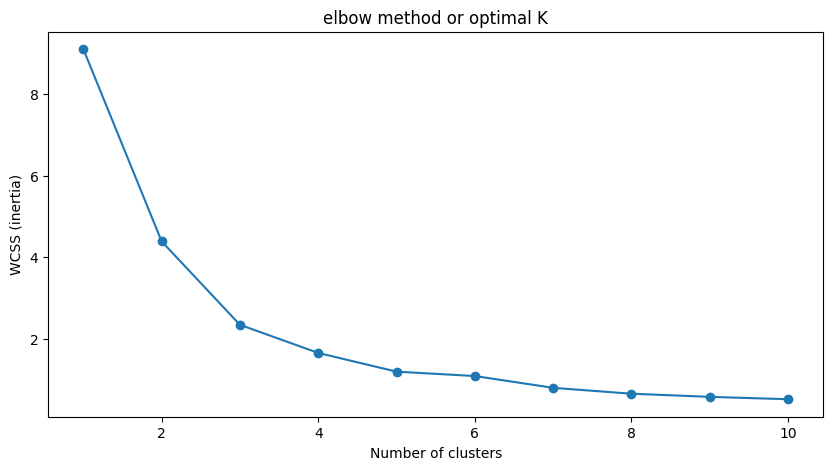

In [6]:
wcss = []
for i in range(1, 11): 
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,5))
plt.plot(range(1,11), wcss, marker="o")
plt.title("elbow method or optimal K")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS (inertia)")
plt.show()

In [7]:
k = 4
kmeans = KMeans(n_clusters=k, init="k-means++", n_init = 10, max_iter = 300, random_state=42)
df["cluster"] = kmeans.fit_predict(x_scaled)
df

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,0
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,0
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,0
...,...,...,...,...,...,...,...,...,...,...,...
162,Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970,1
163,Venezuela,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500,0
164,Vietnam,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310,0
165,Yemen,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310,0


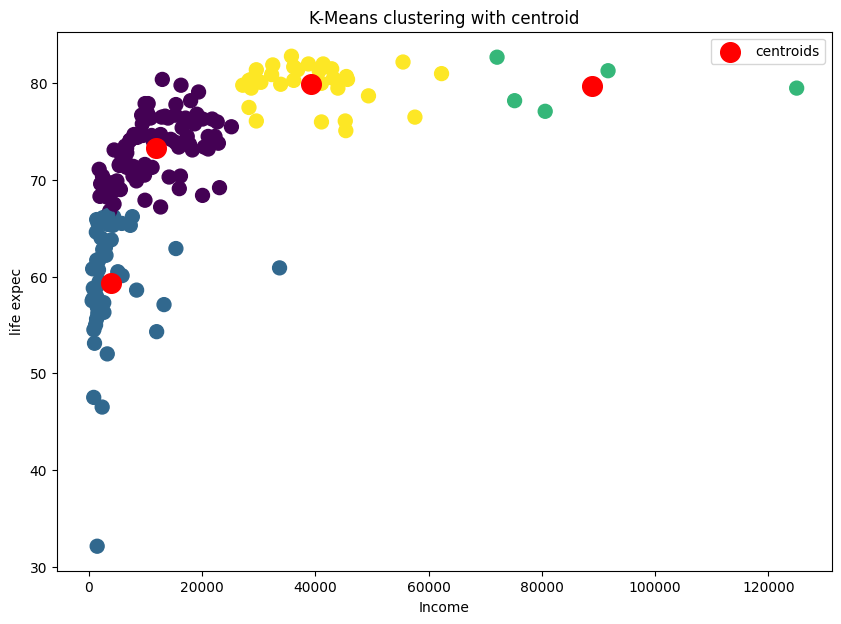

In [8]:
centroids = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids)

plt.figure(figsize=(10,7))
plt.scatter(df["income"], df["life_expec"], c = df["cluster"], s = 100)
plt.scatter(centroids_original[:, 0], centroids_original[:, 1], s = 200, c = "red", label = "centroids")
plt.xlabel("Income")
plt.ylabel("life expec")
plt.title("K-Means clustering with centroid")
plt.legend()
plt.show()

In [9]:
score = silhouette_score(x_scaled, df["cluster"])
print(f"Skor = {score:.2f}")

Skor = 0.52
